# STFT filtering: interactive bandpass filters with spectral windows

A companion to [`stft-examples.ipynb`](https://github.com/MTG/sms-tools-materials/blob/main/examples/stft-examples.ipynb).
Here we analyze a sound using the **short-time Fourier transform (STFT)**, design a frequency-domain bandpass filter, and apply it with
[`smstools.transformations.stftTransformations.stftFiltering`](https://github.com/MTG/sms-tools/blob/master/smstools/transformations/stftTransformations.py).

**What to explore**
1. Listen to the original sound and inspect its spectrogram.
2. Move the **center frequency** and **bandwidth** sliders to select different frequency regions.
3. Choose the **shape of the spectral filter**: rectangular, Hann, Hamming, Blackman, or Tukey.
4. For **Tukey**, vary the taper amount, from rectangular to Hann-like.
5. Compare filter curves, spectrograms, and audio to investigate the tradeoff between sharp frequency selection and time-domain ringing.

**Two different windows:** the STFT uses a **Hamming *time-domain analysis* window** as in the original notebook. The dropdown introduced here controls the **frequency-domain bandpass shape**, not the STFT analysis window.

Run this notebook from `sms-tools-materials/examples/`, so that `../sounds/piano.wav` and `plot_helpers.py` are available.
Install the normal repository requirements plus `ipywidgets` if needed (`pip install ipywidgets`).

## 1. Import libraries

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import IPython.display as ipd
from IPython.display import display
from scipy.signal import get_window
import ipywidgets as widgets

from smstools.models import utilFunctions as UF
from smstools.models import stft as STFT
from smstools.transformations import stftTransformations as STFTT
import plot_helpers as PH

PH.setup_plot_style()

## 2. Load the audio and inspect the waveform

Use another **mono WAV** file by changing `input_file`.

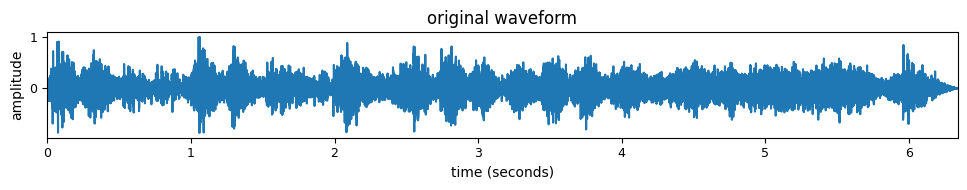

Sample rate: 44100 Hz  |  Duration: 6.34 s


In [9]:
input_file = '../sounds/orchestra.wav'
fs, x = UF.wavread(input_file)
x = np.asarray(x, dtype=float)

fig, ax = plt.subplots(figsize=(10, 2))
PH.plot_waveform(ax, x, fs, title='original waveform', xlabel='time (seconds)')
plt.tight_layout()
plt.show()

print(f'Sample rate: {fs} Hz  |  Duration: {len(x) / fs:.2f} s')
display(ipd.Audio(data=x, rate=fs, normalize=False))

## 3. Analyze the sound using the STFT

The same parameters as in `stft-examples.ipynb` are used: **Hamming window**, **$M=1001$**, **$N=1024$** and **$H=500$** samples.
The analysis produces magnitude spectra in dB (`mX`) and phase spectra in radians (`pX`).

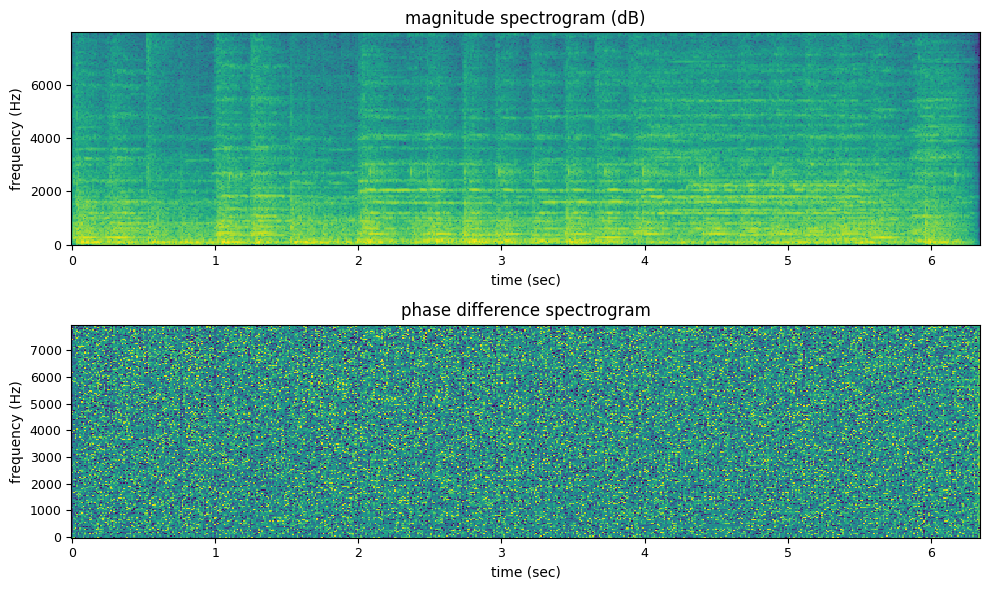

In [10]:
window = 'hamming'
M = 1001
N = 1024
H = 500
max_plot_freq = min(8000.0, fs / 2)  # range shown in the interactive plots

w = get_window(window, M, fftbins=False)
mX, pX = STFT.stftAnal(x, w, N, H)

fig, axes = plt.subplots(2, 1, figsize=(10, 6))
PH.plot_stft_mag_phase(axes, mX, pX, fs, N, H, max_plot_freq=max_plot_freq)
plt.tight_layout()
plt.show()

## 4. Design a bandpass filter with different spectral windows

The original bandpass used a **rectangular spectral mask**: gain **0 dB** in the passband and **−80 dB** outside. Its abrupt frequency edges can produce oscillatory ringing in time. We can soften the edges by shaping the **linear-amplitude** filter with a window and then converting its gain to dB.

For center frequency $f_c$ and bandwidth $B$, the *nominal* band edges are

$$ f_{\mathrm{low}} = f_c - \frac{B}{2},\qquad
   f_{\mathrm{high}} = f_c + \frac{B}{2}. $$

The response is only evaluated at the nonnegative FFT-bin frequencies $f_k=k f_s/N$, from 0 Hz to Nyquist. The part of the nominal band that lies outside this range is clipped.

Define the normalized position inside the nominal band as

$$u_k=\frac{f_k-f_{\mathrm{low}}}{B},\qquad 0\le u_k\le 1.$$

For example, the **Hann** spectral shape is

$$ W_{\mathrm{Hann}}(u)=\tfrac12\bigl[1-\cos(2\pi u)\bigr]. $$

We form a bounded linear gain $A[k]$ equal to this window *inside the band* and an attenuation floor outside; then provide

$$G[k]=20\log_{10}\!\left(\max\left[A[k],\,10^{G_{\mathrm{stop}}/20}\right]\right)$$

to `stftFiltering`, where $G_{\mathrm{stop}}=-80$ dB. Per STFT frame, the transformation adds that gain to the magnitude spectrum in dB and preserves the phase:

$$m_Y(t,k)=m_X(t,k)+G[k],\qquad p_Y(t,k)=p_X(t,k).$$

**Shapes and tradeoff:**
- **Rectangular:** flat passband, sharpest edges, usually the most noticeable ringing.
- **Hann / Blackman:** smooth edges, less ringing, but most of the nominal band is tapered (less uniform passband).
- **Hamming:** partial taper; its nonzero end values still produce an abrupt transition to the stopband.
- **Tukey:** flat center plus smooth edges. **Taper $\alpha=0$** is rectangular; **$\alpha=1$** is Hann-like. Intermediate values are useful for balancing ringing and preserving a flat passband.

**Important:** This is a *spectral mask applied frame by frame*, not a conventional window-designed FIR filter. Smooth spectral edges can reduce ringing from abrupt masking, but cannot remove all STFT reconstruction artifacts. The exact time-domain behavior also depends on $N$, the analysis window, and $H$.

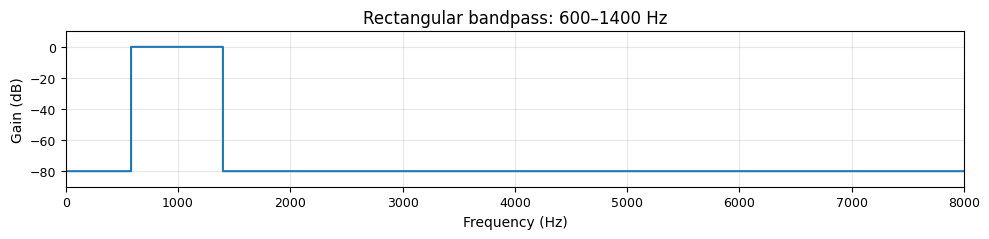

In [11]:
frequencies = np.arange(N // 2 + 1) * fs / N  # DC through Nyquist

# Dense window shape, sampled at the FFT bin frequencies using interpolation.
# Using the nominal (unclipped) band keeps the window centered at the requested fc.
WINDOW_OPTIONS = ('Rectangular', 'Hann', 'Hamming', 'Blackman', 'Tukey')


def make_bandpass_filter(center_hz, bandwidth_hz, window_type='Rectangular',
                         taper=0.5, stop_db=-80.0):
    '''Create a magnitude response in dB for stftFiltering.

    center_hz, bandwidth_hz : nominal band center and total width, in Hz
    window_type : Rectangular, Hann, Hamming, Blackman, or Tukey
    taper : Tukey alpha (0=rectangular, 1=Hann); unused for other types
    stop_db : attenuation floor in dB

    Returns
    -------
    filter_db : ndarray of shape (N//2+1,)
    low_hz, high_hz : nominal band edges, clipped to [0, fs/2]
    '''
    if bandwidth_hz <= 0:
        raise ValueError('Bandwidth must be positive.')
    if window_type not in WINDOW_OPTIONS:
        raise ValueError(f'Unknown window type: {window_type}')
    if not 0.0 <= taper <= 1.0:
        raise ValueError('Tukey taper must be between 0 and 1.')
    if stop_db >= 0:
        raise ValueError('stop_db must be negative.')

    nominal_low = center_hz - bandwidth_hz / 2.0
    nominal_high = center_hz + bandwidth_hz / 2.0
    low_hz = max(0.0, nominal_low)
    high_hz = min(fs / 2.0, nominal_high)

    floor_linear = 10.0 ** (stop_db / 20.0)
    gain = np.full(frequencies.shape, floor_linear, dtype=float)
    u = (frequencies - nominal_low) / bandwidth_hz
    in_band = (u >= 0.0) & (u <= 1.0)

    if window_type == 'Rectangular':
        gain[in_band] = 1.0
    else:
        window_name = (('tukey', taper) if window_type == 'Tukey'
                       else window_type.lower())
        window_profile = get_window(window_name, 2049, fftbins=False)
        unit_positions = np.linspace(0.0, 1.0, len(window_profile))
        gain[in_band] = np.interp(u[in_band], unit_positions, window_profile)

    # Convert linear magnitude -> dB, with a finite attenuation floor.
    filter_db = 20.0 * np.log10(np.maximum(gain, floor_linear))
    return filter_db, low_hz, high_hz


# Initial example: rectangular response, as in the first version of this notebook.
filter_db, low_hz, high_hz = make_bandpass_filter(1000, 800)
fig, ax = plt.subplots(figsize=(10, 2.5))
ax.step(frequencies, filter_db, where='mid')
ax.set(xlim=(0, max_plot_freq), ylim=(-90, 10),
       xlabel='Frequency (Hz)', ylabel='Gain (dB)',
       title=f'Rectangular bandpass: {low_hz:.0f}–{high_hz:.0f} Hz')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Compare spectral shapes at the same center frequency and bandwidth

The following figure shows the *same nominal band* with different spectral windows. **Tukey** can preserve a flat central passband while smoothing its edges. **Hann** and **Blackman** taper practically the whole band.

For an additional *illustration* of ringing, the second plot shows the inverse DFT of each symmetric magnitude mask. This is **not** the exact impulse response of the full framewise STFT processor, but it is useful for seeing the tradeoff between sharp spectral edges and temporal spreading.

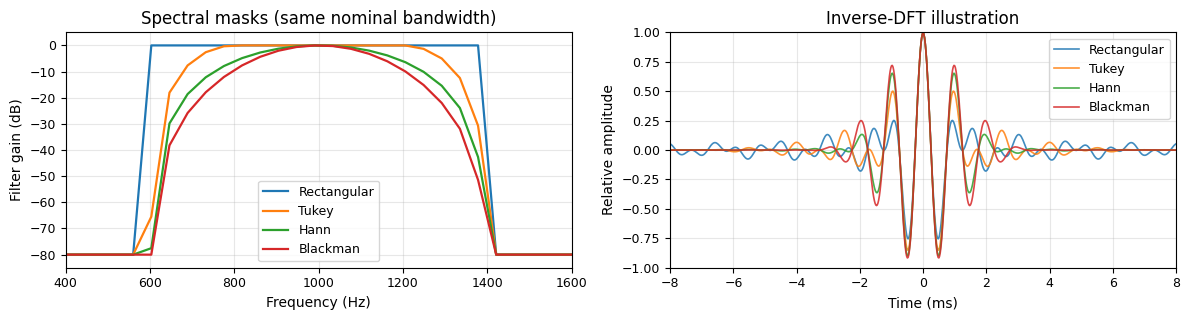

In [12]:
compare_center = 1000.0
compare_bandwidth = 800.0
compare_specs = [('Rectangular', 0.5), ('Tukey', 0.5),
                 ('Hann', 0.5), ('Blackman', 0.5)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.3))
impulse_times_ms = (np.arange(N) - N // 2) * 1000.0 / fs

for name, taper in compare_specs:
    response_db, _, _ = make_bandpass_filter(compare_center, compare_bandwidth,
                                            window_type=name, taper=taper)
    ax1.plot(frequencies, response_db, label=name, lw=1.6)

    linear_gain = 10.0 ** (response_db / 20.0)
    impulse = np.fft.fftshift(np.fft.irfft(linear_gain, n=N))
    impulse /= max(np.max(np.abs(impulse)), 1e-12)  # compare shapes
    ax2.plot(impulse_times_ms, impulse, label=name, lw=1.2, alpha=0.85)

ax1.set(xlim=(400, 1600), ylim=(-85, 5), xlabel='Frequency (Hz)',
        ylabel='Filter gain (dB)', title='Spectral masks (same nominal bandwidth)')
ax2.set(xlim=(-8, 8), ylim=(-1, 1), xlabel='Time (ms)',
        ylabel='Relative amplitude', title='Inverse-DFT illustration')
for ax in (ax1, ax2):
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

## 5. Interactive STFT bandpass filtering

Change the **center**, **bandwidth**, and **spectral window**. For **Tukey**, adjust the taper slider (**0 = rectangular**, **1 = Hann-like**). The Tukey slider has no effect for other window shapes.

Each change calls **`STFTT.stftFiltering(...)`** with the newly computed **dB frequency response**. The original and filtered spectrograms share the same dB color scale. The two audio players also use the **same playback gain** so you can hear changes in level (a smoother mask may retain less energy).

The dashed lines in the spectrograms show the **nominal edges**; with a tapered window, frequencies close to those lines are attenuated. For very narrow bands, $N$ limits how accurately the shapes can be represented: at $f_s=44{,}100$ Hz and $N=1024$, adjacent FFT bins are about 43 Hz apart.

In [13]:
# Data for plotting. The original STFT is computed only once for visualization.
frame_times = np.arange(mX.shape[0]) * H / fs
shown_bins = np.flatnonzero(frequencies <= max_plot_freq)
plot_freqs = frequencies[shown_bins]
mag_max = float(np.percentile(mX, 99.5))
mag_min = mag_max - 80.0

# Keep the most recently filtered output available in this notebook.
last_result = {}


def update_bandpass(center_frequency, bandwidth, spectral_window, tukey_taper):
    filter_db, low_hz, high_hz = make_bandpass_filter(
        center_frequency, bandwidth, window_type=spectral_window,
        taper=tukey_taper
    )

    # Actual SMS-tools transformation: analysis -> modify magnitudes -> synthesis.
    y = STFTT.stftFiltering(x, fs, w, N, H, filter_db)
    last_result.update(y=y, filter_db=filter_db,
                       center_hz=center_frequency, bandwidth_hz=bandwidth,
                       window=spectral_window, taper=tukey_taper)

    # Expected modified magnitude spectrogram (same dB gains applied per frame).
    mY = mX + filter_db[np.newaxis, :]
    fig, axes = plt.subplots(3, 1, figsize=(10, 9), constrained_layout=True)

    axes[0].step(frequencies, filter_db, where='mid', color='tab:blue')
    axes[0].axvline(center_frequency, ls=':', color='tab:orange', label='center')
    axes[0].axvline(low_hz, ls='--', color='0.45', label='nominal edges')
    axes[0].axvline(high_hz, ls='--', color='0.45')
    title = f'{spectral_window} spectral bandpass: {low_hz:.0f}–{high_hz:.0f} Hz'
    if spectral_window == 'Tukey':
        title += f' (taper α={tukey_taper:.2f})'
    axes[0].set(xlim=(0, max_plot_freq), ylim=(-90, 10),
                xlabel='Frequency (Hz)', ylabel='Gain (dB)', title=title)
    axes[0].grid(True, alpha=0.25)
    axes[0].legend(loc='lower right')

    spec_kwargs = dict(shading='auto', vmin=mag_min, vmax=mag_max, cmap='viridis')
    axes[1].pcolormesh(frame_times, plot_freqs, mX[:, shown_bins].T, **spec_kwargs)
    im = axes[2].pcolormesh(frame_times, plot_freqs, mY[:, shown_bins].T, **spec_kwargs)

    for ax, title in zip(axes[1:], ['Original magnitude spectrogram',
                                    'Filtered magnitude spectrogram']):
        ax.axhline(low_hz, ls='--', color='white', lw=0.9, alpha=0.8)
        ax.axhline(high_hz, ls='--', color='white', lw=0.9, alpha=0.8)
        ax.set(xlabel='Time (s)', ylabel='Frequency (Hz)',
               title=title, ylim=(0, max_plot_freq))

    fig.colorbar(im, ax=axes[1:], label='Magnitude (dB)', shrink=0.85)
    plt.show()

    rms_in = np.sqrt(np.mean(x**2))
    rms_out = np.sqrt(np.mean(y**2))
    relative_db = 20 * np.log10(max(rms_out, 1e-12) / max(rms_in, 1e-12))
    print(f'Nominal passband: {low_hz:.0f}–{high_hz:.0f} Hz  |  '
          f'Window: {spectral_window}  |  Output RMS vs input: {relative_db:+.1f} dB')

    # Identical gain for both players; prevent clipping on playback.
    common_scale = max(1.0, np.max(np.abs(x)), np.max(np.abs(y)))
    print('Original audio:')
    display(ipd.Audio(data=x / common_scale, rate=fs, normalize=False))
    print('Filtered audio:')
    display(ipd.Audio(data=y / common_scale, rate=fs, normalize=False))


control_style = {'description_width': '115px'}
control_layout = widgets.Layout(width='500px')
center_slider = widgets.FloatSlider(
    value=min(1000.0, max_plot_freq), min=0.0, max=max_plot_freq,
    step=50.0, description='Center (Hz)',
    continuous_update=False, readout_format='.0f',
    style=control_style, layout=control_layout
)
bandwidth_slider = widgets.FloatSlider(
    value=min(800.0, max_plot_freq), min=50.0, max=max_plot_freq,
    step=50.0, description='Bandwidth (Hz)',
    continuous_update=False, readout_format='.0f',
    style=control_style, layout=control_layout
)
window_dropdown = widgets.Dropdown(
    options=WINDOW_OPTIONS, value='Tukey', description='Spectral window',
    style=control_style, layout=control_layout
)
taper_slider = widgets.FloatSlider(
    value=0.5, min=0.0, max=1.0, step=0.05,
    description='Tukey taper α', continuous_update=False,
    readout_format='.2f', style=control_style, layout=control_layout
)

interactive_plot = widgets.interactive_output(
    update_bandpass,
    {'center_frequency': center_slider, 'bandwidth': bandwidth_slider,
     'spectral_window': window_dropdown, 'tukey_taper': taper_slider}
)
display(widgets.VBox([center_slider, bandwidth_slider, window_dropdown,
                      taper_slider]), interactive_plot)

Output()

## 6. Things to try

- Fix **center = 1000 Hz**, **bandwidth = 800 Hz** and compare **Rectangular**, **Hann**, **Hamming**, and **Blackman**. How do the spectrogram and audible sound change?
- Select **Tukey** and gradually move the **taper** slider from **0** to **1**. At which setting does ringing become less noticeable, and how does the remaining passband change?
- Try **bandwidth = 200 Hz** with different shapes. With so few FFT bins in the passband, why are the filter shapes less distinct? Would increasing $N$ help?
- Shift the center frequency across different piano partials. How does the choice of window affect the loudness and character of what remains?
- Set the center close to **0 Hz** or **Nyquist**. What happens when one side of the *nominal* band is outside the available frequencies?

**Questions:** What is the tradeoff between steep frequency selection and time-domain ringing? Why does the same nominal bandwidth not imply the same effective −3 dB bandwidth for all windows? Why can a Hann-shaped filter sound quieter than a rectangular filter with the same bandwidth?

**Limitations:** A smoother filter response generally reduces ringing associated with abrupt frequency-domain masking, but it broadens the transition and may change the retained level. `stftFiltering()` is applied independently to each STFT frame; the exact outcome depends on FFT size, analysis window, hop size and framewise phase. This is **not** a general-purpose linear-phase FIR filter design.

### Optional: save the most recent filtered sound

Run the following cell after moving the sliders, if you want to keep the filtered audio.

In [14]:
# Uncomment to save the last processed sound as a floating-point WAV file.
# from scipy.io import wavfile
# wavfile.write('stft_bandpass_output.wav', fs,
#               np.asarray(last_result['y'], dtype=np.float32))